In [11]:
!nvidia-smi

Thu Nov 26 23:03:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [12]:
import torch, sys
print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
    print("VRAM (Go) :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

Python : 3.13.16
PyTorch : 2.14.1+cu130
CUDA disponible : True
GPU : Tesla T4
VRAM (Go) : 15.6


In [13]:
!pip install -q transformers pillow matplotlib pycocotools supervision

In [14]:
import transformers, torch
print("transformers :", transformers.__version__)
print("torch        :", torch.__version__)

from transformers import (
    AutoProcessor, AutoModelForZeroShotObjectDetection,
    Sam2Model, Sam2Processor,
)
print("Imports OK : Grounding DINO + SAM 2")

transformers : 5.22.1
torch        : 2.14.1+cu130
Imports OK : Grounding DINO + SAM 2


In [15]:
import inspect
import torch
import requests
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

device = "cuda"
model_id = "IDEA-Research/grounding-dino-tiny"

processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id).to(device)
model.eval()

# On inspecte la signature réelle de la fonction de post-traitement
params = list(inspect.signature(processor.post_process_grounded_object_detection).parameters)
print("Paramètres de post_process_grounded_object_detection :", params)
print("VRAM utilisée (Go) :", round(torch.cuda.memory_allocated() / 1e9, 2))

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Paramètres de post_process_grounded_object_detection : ['outputs', 'input_ids', 'threshold', 'text_threshold', 'target_sizes', 'text_labels']
VRAM utilisée (Go) : 0.69


Nom du seuil de boîte utilisé : threshold
Clés du résultat : ['scores', 'boxes', 'text_labels', 'labels']
Nombre de détections : 2
[345.0, 23.2, 637.5, 374.0] score = 0.448
[11.9, 51.7, 316.6, 473.1] score = 0.436


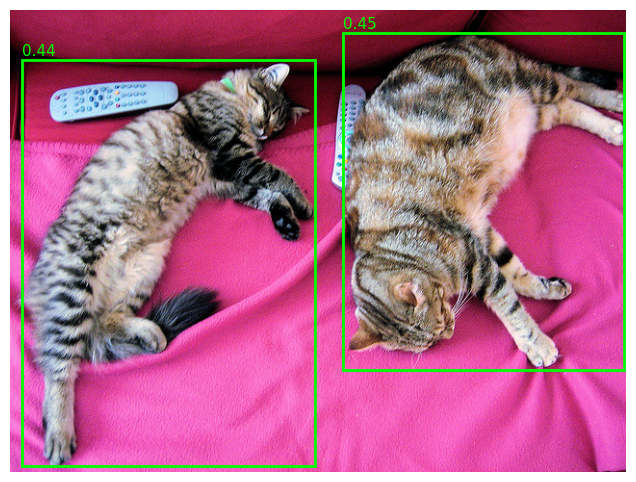

In [16]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(requests.get(url, stream=True).raw).convert("RGB")

text = "a cat."  # minuscules, point final

inputs = processor(images=image, text=text, return_tensors="pt").to(device)
with torch.no_grad():
    outputs = model(**inputs)

# Construit les arguments selon les noms réellement disponibles
kwargs = {"target_sizes": [image.size[::-1]]}   # (hauteur, largeur)
box_key = "threshold" if "threshold" in params else "box_threshold"
kwargs[box_key] = 0.3
if "text_threshold" in params:
    kwargs["text_threshold"] = 0.3
print("Nom du seuil de boîte utilisé :", box_key)

results = processor.post_process_grounded_object_detection(
    outputs, inputs.input_ids, **kwargs
)[0]

print("Clés du résultat :", list(results.keys()))
print("Nombre de détections :", len(results["boxes"]))
for box, score in zip(results["boxes"], results["scores"]):
    print([round(v, 1) for v in box.tolist()], "score =", round(score.item(), 3))

# Affichage
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(image)
for box, score in zip(results["boxes"], results["scores"]):
    x0, y0, x1, y1 = box.tolist()
    ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                   fill=False, edgecolor="lime", linewidth=2))
    ax.text(x0, y0 - 4, f"{score.item():.2f}", color="lime", fontsize=11)
ax.axis("off")
plt.show()

In [17]:
from transformers import Sam2Model, Sam2Processor

sam_id = "facebook/sam2.1-hiera-small"
sam_processor = Sam2Processor.from_pretrained(sam_id)
sam_model = Sam2Model.from_pretrained(sam_id).to(device)
sam_model.eval()

print("VRAM utilisée (Go) :", round(torch.cuda.memory_allocated() / 1e9, 2))

processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  184MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/357 [00:00<?, ?it/s]

VRAM utilisée (Go) : 0.92


Boîtes passées à SAM 2 : [[[344.9630432128906, 23.163785934448242, 637.5407104492188, 374.0405578613281], [11.874551773071289, 51.742286682128906, 316.61273193359375, 473.0727233886719]]]
Forme des masques : (2, 1, 480, 640) | type : torch.bool
Masques booléens : (2, 480, 640)
  masque 0 : 57311 pixels (18.7 % de l'image)
  masque 1 : 48707 pixels (15.9 % de l'image)


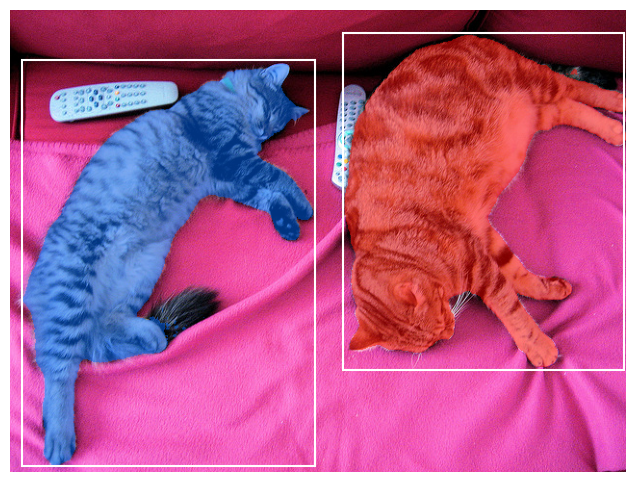

In [18]:
import numpy as np

# Boîtes de Grounding DINO -> liste de listes de floats
boxes = [b.tolist() for b in results["boxes"]]
input_boxes = [boxes]   # [image][boîtes][4]
print("Boîtes passées à SAM 2 :", input_boxes)

sam_inputs = sam_processor(
    images=image, input_boxes=input_boxes, return_tensors="pt"
).to(device)

with torch.no_grad():
    sam_outputs = sam_model(**sam_inputs, multimask_output=False)

masks = sam_processor.post_process_masks(
    sam_outputs.pred_masks.cpu(), sam_inputs["original_sizes"]
)[0]

print("Forme des masques :", tuple(masks.shape), "| type :", masks.dtype)

# Normalise : un masque booléen 2D par boîte
m = masks[:, 0] if masks.ndim == 4 else masks
if m.dtype != torch.bool:
    m = m > 0
m = m.numpy()
print("Masques booléens :", m.shape)
for i, mask in enumerate(m):
    print(f"  masque {i} : {mask.sum()} pixels ({100 * mask.mean():.1f} % de l'image)")

# Affichage : image + masques colorés + boîtes
colors = [(1, 0, 0), (0, 0.4, 1), (0, 0.7, 0), (1, 0.6, 0)]
overlay = np.array(image).astype(float) / 255
for i, mask in enumerate(m):
    c = np.array(colors[i % len(colors)])
    overlay[mask] = 0.5 * overlay[mask] + 0.5 * c

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(overlay)
for box in boxes:
    x0, y0, x1, y1 = box
    ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                   fill=False, edgecolor="white", linewidth=1.5))
ax.axis("off")
plt.show()

In [19]:
!git clone https://github.com/YalaIslem/openseg-r.git
import sys
sys.path.insert(0, "/content/openseg-r/src")

fatal: destination path 'openseg-r' already exists and is not an empty directory.


In [20]:
import torch
from openseg.pipeline import OpenVocabSegmenter

# Libère les anciens modèles du notebook (la classe recharge les siens)
for name in ("model", "sam_model"):
    globals().pop(name, None)
torch.cuda.empty_cache()

seg = OpenVocabSegmenter()

out = seg(image, "a cat")
print("Détections :", len(out["boxes"]))
print("Scores     :", out["scores"].round(3))
print("Labels     :", out["labels"])
print("Pixels par masque :", [int(m.sum()) for m in out["masks"]])

# Cas limite : texte sans objet correspondant, seuil élevé
out2 = seg(image, "a bottle", box_threshold=0.5)
print("Cas limite :", len(out2["boxes"]), "détection(s), masques", out2["masks"].shape)

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/357 [00:00<?, ?it/s]

Détections : 2
Scores     : [0.448 0.436]
Labels     : ['a cat', 'a cat']
Pixels par masque : [57311, 48707]
Cas limite : 0 détection(s), masques (0, 480, 640)


In [21]:
from google.colab import drive
drive.mount("/content/drive")



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
!cd /content/openseg-r && git pull

Already up to date.


bouteille.jpg   | texte='plastic bottle' | 1 détection(s) | scores=[0.949999988079071]


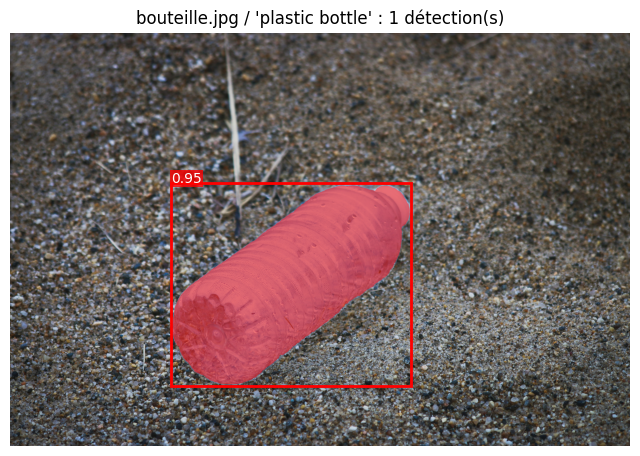

canette.jpg     | texte='can' | 1 détection(s) | scores=[0.4099999964237213]


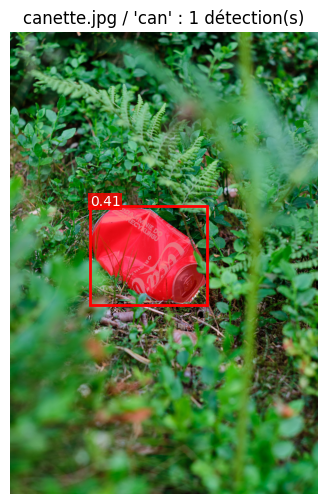

sac.jpg         | texte='plastic bag' | 1 détection(s) | scores=[0.9200000166893005]


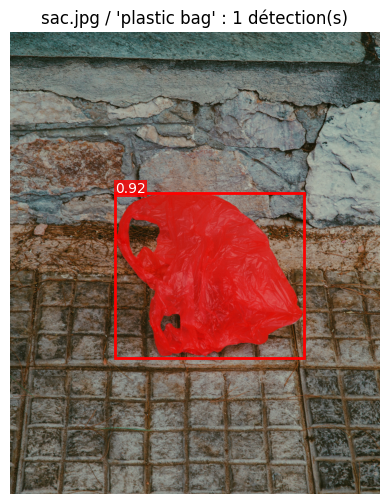

megot.jpg       | texte='cigarette butt' | 4 détection(s) | scores=[0.5099999904632568, 0.41999998688697815, 0.33000001311302185, 0.36000001430511475]


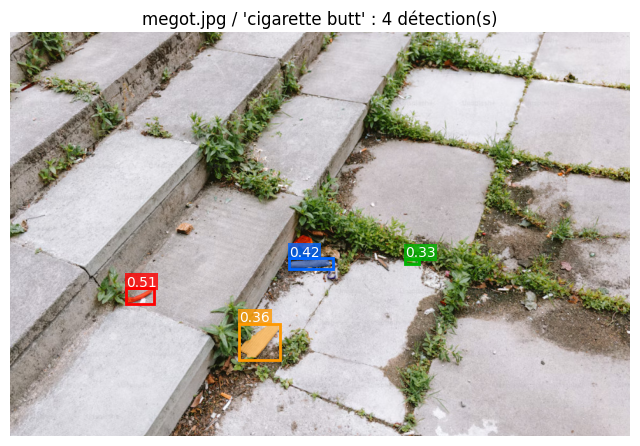

scene.jpg       | texte='plastic bottle' | 31 détection(s) | scores=[0.5799999833106995, 0.49000000953674316, 0.4399999976158142, 0.41999998688697815, 0.49000000953674316, 0.49000000953674316, 0.4099999964237213, 0.44999998807907104, 0.38999998569488525, 0.47999998927116394, 0.3499999940395355, 0.38999998569488525, 0.46000000834465027, 0.3199999928474426, 0.36000001430511475, 0.3799999952316284, 0.3799999952316284, 0.3199999928474426, 0.3400000035762787, 0.3100000023841858, 0.33000001311302185, 0.3100000023841858, 0.33000001311302185, 0.30000001192092896, 0.3100000023841858, 0.3100000023841858, 0.33000001311302185, 0.3199999928474426, 0.3400000035762787, 0.3100000023841858, 0.3100000023841858]


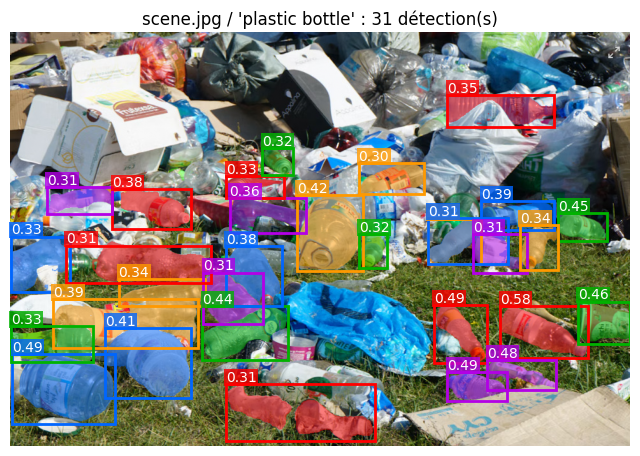

In [25]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from openseg.viz import show_result

SAMPLES_DIR = Path("/content/drive/MyDrive/openseg-r/data/samples")
OUT_DIR = Path("/content/drive/MyDrive/openseg-r/results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# À ADAPTER : (nom du fichier, texte à chercher)
samples = [
    ("bouteille.jpg", "plastic bottle"),
    ("canette.jpg",   "can"),
    ("sac.jpg",       "plastic bag"),
    ("megot.jpg",     "cigarette butt"),
    ("scene.jpg",     "plastic bottle"),
]

for fname, text in samples:
    img = Image.open(SAMPLES_DIR / fname).convert("RGB")
    out = seg(img, text, box_threshold=0.3)
    print(f"{fname:15s} | texte='{text}' | {len(out['boxes'])} détection(s) | "
          f"scores={out['scores'].round(2).tolist()}")
    fig, ax = plt.subplots(figsize=(8, 6))
    show_result(img, out, title=f"{fname} / '{text}'", ax=ax)
    fig.savefig(OUT_DIR / f"phase1_{Path(fname).stem}.png", dpi=120, bbox_inches="tight")
    plt.show()

In [26]:
import numpy as np
scene = Image.open(SAMPLES_DIR / "scene.jpg").convert("RGB")
boxes, scores, labels = seg.detect(scene, "plastic bottle", box_threshold=0.3)

print("Résolution de l'image :", scene.size)
for t in (0.3, 0.4, 0.5):
    print(f"seuil {t} : {(scores >= t).sum()} boîtes")

# Taille relative des boîtes (part de l'image)
W, H = scene.size
areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]) / (W * H)
print("Surface des boîtes (min / médiane / max, en % de l'image) :",
      round(100 * areas.min(), 2), "/", round(100 * float(np.median(areas)), 2), "/",
      round(100 * areas.max(), 2))

Résolution de l'image : (973, 649)
seuil 0.3 : 31 boîtes
seuil 0.4 : 10 boîtes
seuil 0.5 : 1 boîtes
Surface des boîtes (min / médiane / max, en % de l'image) : 0.32 / 1.15 / 3.31


In [27]:
from importlib.metadata import version, PackageNotFoundError
import sys

pkgs = ["transformers", "torch", "torchvision", "pillow", "numpy",
        "matplotlib", "pycocotools", "supervision", "accelerate"]

lines = []
for p in pkgs:
    try:
        v = version(p).split("+")[0]   # retire le suffixe CUDA (+cu130)
        lines.append(f"{p}=={v}")
    except PackageNotFoundError:
        lines.append(f"# {p} : non installé ici")

print(f"# Testé avec Python {sys.version.split()[0]} (Google Colab, GPU Tesla T4)")
print("\n".join(lines))

# Testé avec Python 3.13.16 (Google Colab, GPU Tesla T4)
transformers==5.22.1
torch==2.14.1
torchvision==0.29.1
pillow==11.3.0
numpy==2.4.6
matplotlib==3.10.0
pycocotools==2.0.11
supervision==0.32.3
accelerate==1.15.0
